## Theorem explanation
1. $f\_n(x) -> f(x)$ pointwise (almost everywhere), and
2. there is a single g with $|f\_n(x)| <= g(x) $ for all n, and $\integ(g) < \ifnty$ (g does not depend on n)

Then $\integ(f\_n) -> \integ(f)$, which means you can pass the limit inside the integral

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import norm

trap = getattr(np, 'trapz', None) 
plt.rcParams["figure.figsize"] = (11, 4)
pd.options.display.float_format = '{:,.6f}'.format

def integrate(func, a, b):
    """Integrate a function from a to b using scipy.integrate.quad."""
    result, error = quad(func, a, b, limit=500)
    return result

def step_integral(g, breakpoints):
    """Exact integral of a function that is constant between breakpoints"""
    b = np.unique(breakpoints)
    mid = (b[1:] + b[:-1]) / 2
    return np.sum(g(mid) * np.diff(b))

def run(f, bp_fn, Ns):
    """For each N: the minimal dominator candidate"""
    results = []
    for N in Ns:
        breakpoints = bp_fn(N)
        ns = np.arange(1, N+1)
        env = lambda x: np.max([np.abs(f(x,n)) for n in ns], axis=0)
        results.append((N, step_integral(lambda x: f(x, N), breakpoints), step_integral(env, breakpoints)))
    return pd.DataFrame(results, columns=['N', 'Integral', 'Dominator'])

H = lambda N : np.sum(1/np.arange(1, N+1)) #harmonic number

### Part A: Cases where DCT works

,N,Integrate,exact 1/(n+1),limit Integ(f)
0,10,0.090909,0.090909,0.000000
1,20,0.047619,0.047619,0.000000
2,50,0.019608,0.019608,0.000000
3,100,0.009901,0.009901,0.000000
4,200,0.004975,0.004975,0.000000
5,500,0.001996,0.001996,0.000000
6,1000,0.000999,0.000999,0.000000


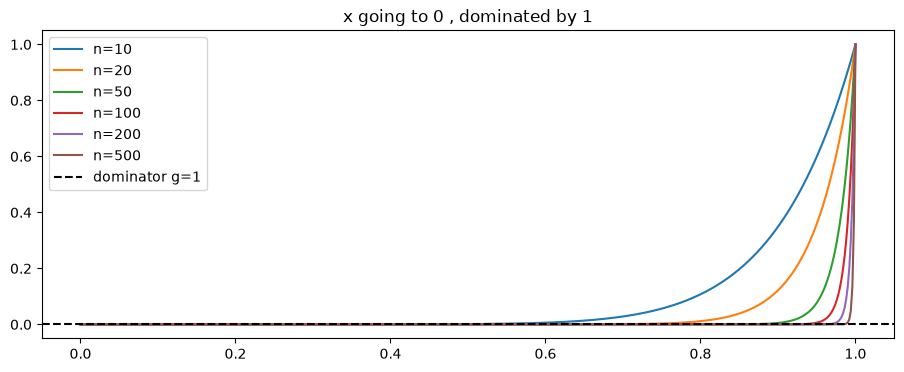

In [3]:
ns = [10, 20, 50, 100, 200, 500, 1000]
df = pd.DataFrame({'N': ns, 'Integrate': [integrate(lambda x: x**n, 0, 1) for n in ns]})
df["exact 1/(n+1)"] = 1/(df["N"] + 1)
df["limit Integ(f)"] = 0.0
display(df)

x = np.linspace(0, 1, 500)
for n in [10, 20, 50, 100, 200, 500]:
    plt.plot(x, x**n, label=f'n={n}')
plt.axhline(0, color='k', ls="--",label="dominator g=1")
plt.title("x going to 0 , dominated by 1"); plt.legend(); plt.show()

In [5]:
f = lambda x, n: np.sinc(x/(n*np.pi))/(1 + x**2) # sinc(x/(n*pi))/(1+x^2)
g = lambda x: 1/(1 + x**2) # dominator g=1/(1+x^2)

xs = np.linspace(0,500, 200001)
print("domination holds for all tested n:",
      np.all([np.all(np.abs(f(xs, n)) <= g(xs)+1e-15) for n in [10, 20, 50, 100, 200, 500]]))

rows = [(n, integrate(lambda x: f(x, n), 0, np.inf)) for n in [10, 20, 50, 100, 200, 500, 1000]]
df = pd.DataFrame(rows, columns=['n', 'Integral']); df["pi/2"]= np.pi/2
display(df)

domination holds for all tested n: True


,n,Integral,pi/2
0,10,1.494810,1.570796
1,20,1.532173,1.570796
2,50,1.555193,1.570796
3,100,1.562968,1.570796
4,200,1.566876,1.570796
5,500,1.569227,1.570796
6,1000,1.570011,1.570796


In [7]:
ns = [10, 20, 50, 100, 200, 500, 1000]
rows = [(n, integrate(lambda x: ((1-x)/n) ** n, 0, n), n / (n+1)) for n in ns]
display(pd.DataFrame(rows, columns=['n', 'Integral', 'exact n/(n+1)']).assign(limit=1.0))

xs = np.linspace(0, 50, 50001)
print("f_n<=e^-x:", np.all(np.all(((1-xs[xs<n]/n)**n) <= np.exp(-xs[xs<n])+1e-15) for n in ns))  


,n,Integral,exact n/(n+1),limit
0,10,0.285282,0.909091,1.000000
1,20,0.324344,0.952381,1.000000
2,50,0.349889,0.980392,1.000000
3,100,0.358784,0.990099,1.000000
4,200,0.363307,0.995025,1.000000
5,500,0.366044,0.998004,1.000000
6,1000,0.366961,0.999001,1.000000


f_n<=e^-x: True


### Case B: Cases where DCT fails

#### Escaping Spike, f_n=n*1_{(0, 1/n)} on (0,1)

,N,Integral,Dominator,H_N (theory)
0,1,1.000000,1.000000,1.000000
1,10,1.000000,2.928968,2.928968
2,100,1.000000,5.187378,5.187378
3,1000,1.000000,7.485471,7.485471


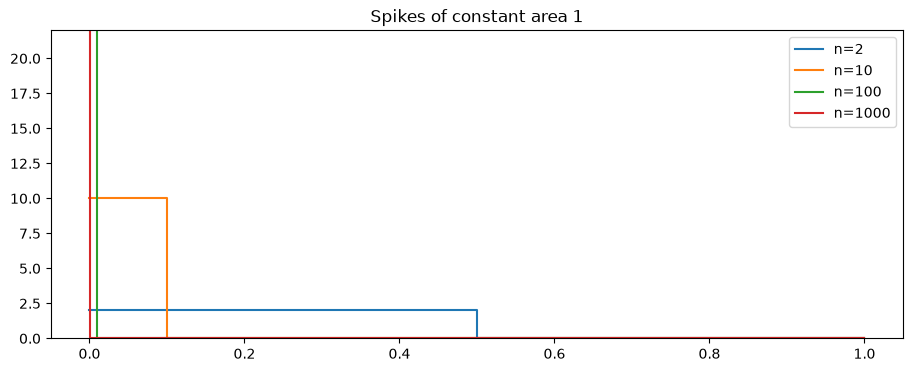

In [8]:
f4 = lambda x, n: n*((x>0) & (x<1/n))
bp4 = lambda N: np.concatenate([[0], 1/np.arange(1, N+1)])
res4 = run(f4, bp4, [1, 10, 100, 1000])
res4["H_N (theory)"] = [H(N) for N in res4["N"]]
display(res4)

x = np.linspace(0, 1, 2000)
for n in [2, 10, 100, 1000]:
    plt.step([0,1/n,1], [n,0,0], where='post', label=f'n={n}')
plt.ylim(0,22);plt.title("Spikes of constant area 1"); plt.legend(); plt.show()

the integral f_N stays at 1, while the integral of sup(f_n) = H_N = ln(N)+0.577 that goes to infinity. So, no dominator exists, and the result isn't 1 . 

Roughly, sup_n(f_n(x)) = 1/x which is not integrable in 0

#### Escaping to infinity, f_n = 1_{[n,n+1]}

Here the mass has constant size but moves away. For every fixed x, f_n(x)=0once n> x

In [10]:
f5 = lambda x,n : ((x>=n) & (x<=n+1)).astype(float)
bp5 = lambda N: np.arange(0, N+2)
display(run(f5, bp5, [1, 10, 100, 1000]))

,N,Integral,Dominator
0,1,1.000000,1.000000
1,10,1.000000,10.000000
2,100,1.000000,100.000000
3,1000,1.000000,"1,000.000000"


the integral of f_N is equal to 1, while the integral of sup of f_n with n<=N, goes to inifinity, the envelope is 1_{1,infinity} which has infinite areas

### DCT is sufficient but not necessary
f_n = (1/n)*1_{[n,n+1]}

In [11]:
f8 = lambda f,n : 1/n*((f>=n) & (f<=n+1))
bp8 = lambda N: np.arange(0, N+2)
res8 = run(f8, bp8, [1, 10, 100, 1000])
res8["H_N (theory)"] = [H(N) for N in res8["N"]]
display(res8)

,N,Integral,Dominator,H_N (theory)
0,1,1.000000,1.000000,1.000000
1,10,0.100000,2.928968,2.928968
2,100,0.010000,5.187378,5.187378
3,1000,0.001000,7.485471,7.485471


the integral of sup f_n is H(N) that goes to infinity, so the hypothesis of DCT fails, yet the integral of f_n converges to 0 anyways. DCT gives sufficient conditions only.

The exact condition for integral f_n to converge to the integral of f uniformally (uniform integrability: Vitali's theorem), which on infinite measure measure spaces also needs tightness.